WEEK 4 – EXPLORATORY DATA ANALYSIS (EDA)

Project: The Code Burnout – AI-Based Analysis of Mental Health in the Tech Industry

Objective:
To explore the dataset using statistical analysis and visualizations to identify patterns and relationships between workplace factors and self-reported mental health experiences.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

clean = pd.read_csv("mental_health_in_tech_2016 (1).csv")

print("Dataset Shape:", clean.shape)
display(clean.head())

Dataset Shape: (1433, 63)


,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?","If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?
0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,...,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,...,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,...,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Sometimes,43,male,United Kingdom,NaN,United Kingdom,NaN,Supervisor/Team Lead,Sometimes
4,0,6-25,0.0,1.0,Yes,Yes,No,No,No,Neither easy nor difficult,...,Sometimes,Sometimes,43,Female,United States of America,Illinois,United States of America,Illinois,Executive Leadership|Supervisor/Team Lead|Dev ...,Sometimes


In [7]:
clean = clean.drop_duplicates()

text_columns = clean.select_dtypes(include='object').columns

for col in text_columns:
    clean[col] = clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("After Cleaning:", clean.shape)

After Cleaning: (1433, 63)


In [8]:
clean.to_csv("cleaned_mental_health.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


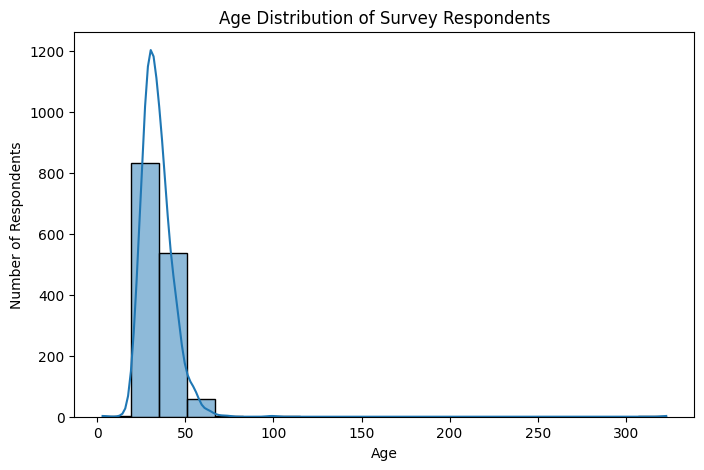

In [15]:
age_col = 'What is your age?'

clean[age_col] = pd.to_numeric(clean[age_col], errors='coerce')

plt.figure(figsize=(8,5))

sns.histplot(clean[age_col].dropna(), bins=20, kde=True)

plt.title("Age Distribution of Survey Respondents")
plt.xlabel("Age")
plt.ylabel("Number of Respondents")

plt.show()

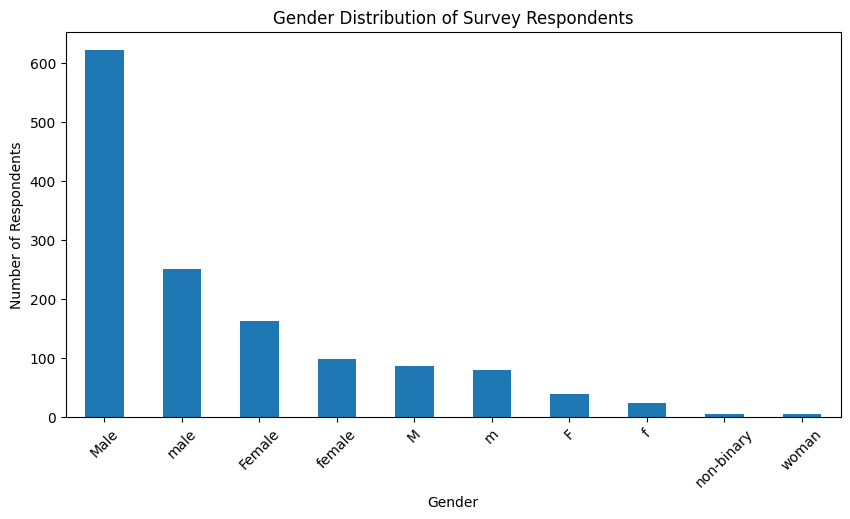

In [17]:
gender_col = 'What is your gender?'

plt.figure(figsize=(10,5))

clean[gender_col].value_counts().head(10).plot(kind='bar')

plt.title("Gender Distribution of Survey Respondents")
plt.xlabel("Gender")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45)

plt.show()

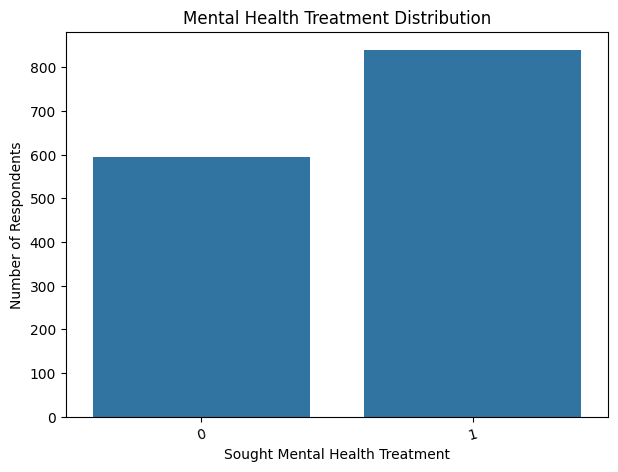

In [19]:
treatment_col = 'Have you ever sought treatment for a mental health issue from a mental health professional?'

plt.figure(figsize=(7,5))

sns.countplot(data=clean, x=treatment_col)

plt.title("Mental Health Treatment Distribution")
plt.xlabel("Sought Mental Health Treatment")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=15)

plt.show()

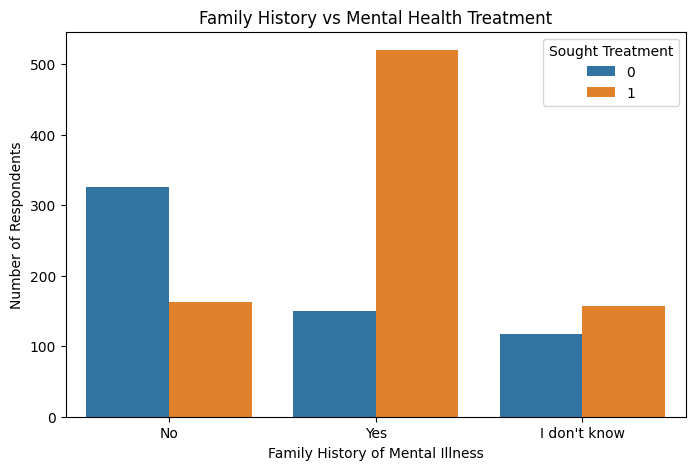

In [21]:
family_col = 'Do you have a family history of mental illness?'

plt.figure(figsize=(8,5))

sns.countplot(data=clean, x=family_col, hue=treatment_col)

plt.title("Family History vs Mental Health Treatment")
plt.xlabel("Family History of Mental Illness")
plt.ylabel("Number of Respondents")
plt.legend(title="Sought Treatment")

plt.show()

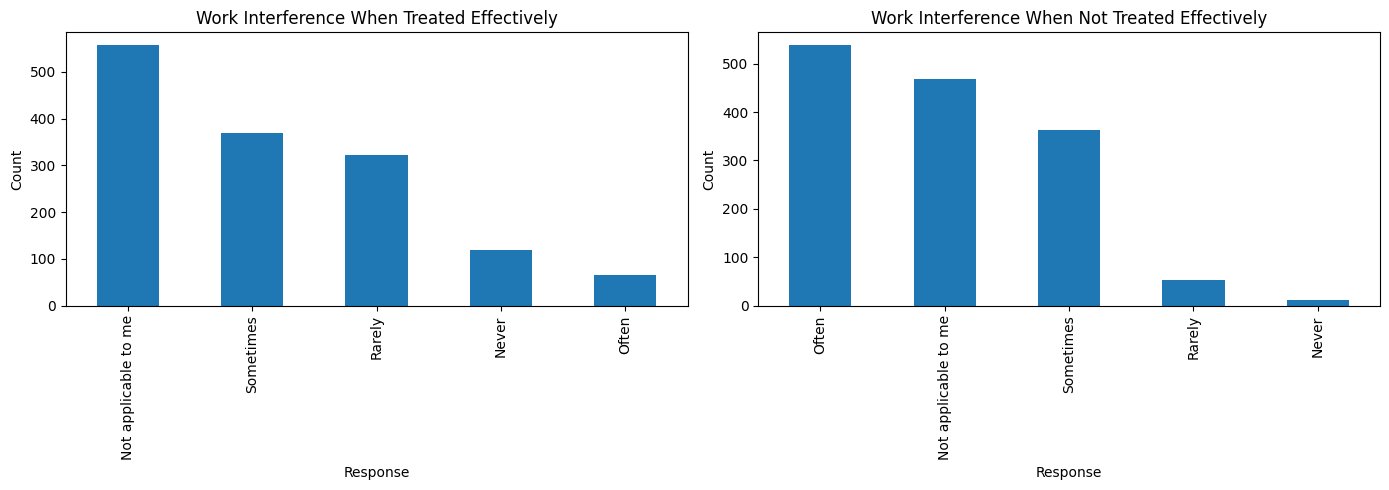

In [24]:
treated_col = 'If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?'

not_treated_col = 'If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

clean[treated_col].value_counts().plot(
    kind='bar', ax=axes[0]
)
axes[0].set_title("Work Interference When Treated Effectively")
axes[0].set_xlabel("Response")
axes[0].set_ylabel("Count")

clean[not_treated_col].value_counts().plot(
    kind='bar', ax=axes[1]
)
axes[1].set_title("Work Interference When Not Treated Effectively")
axes[1].set_xlabel("Response")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

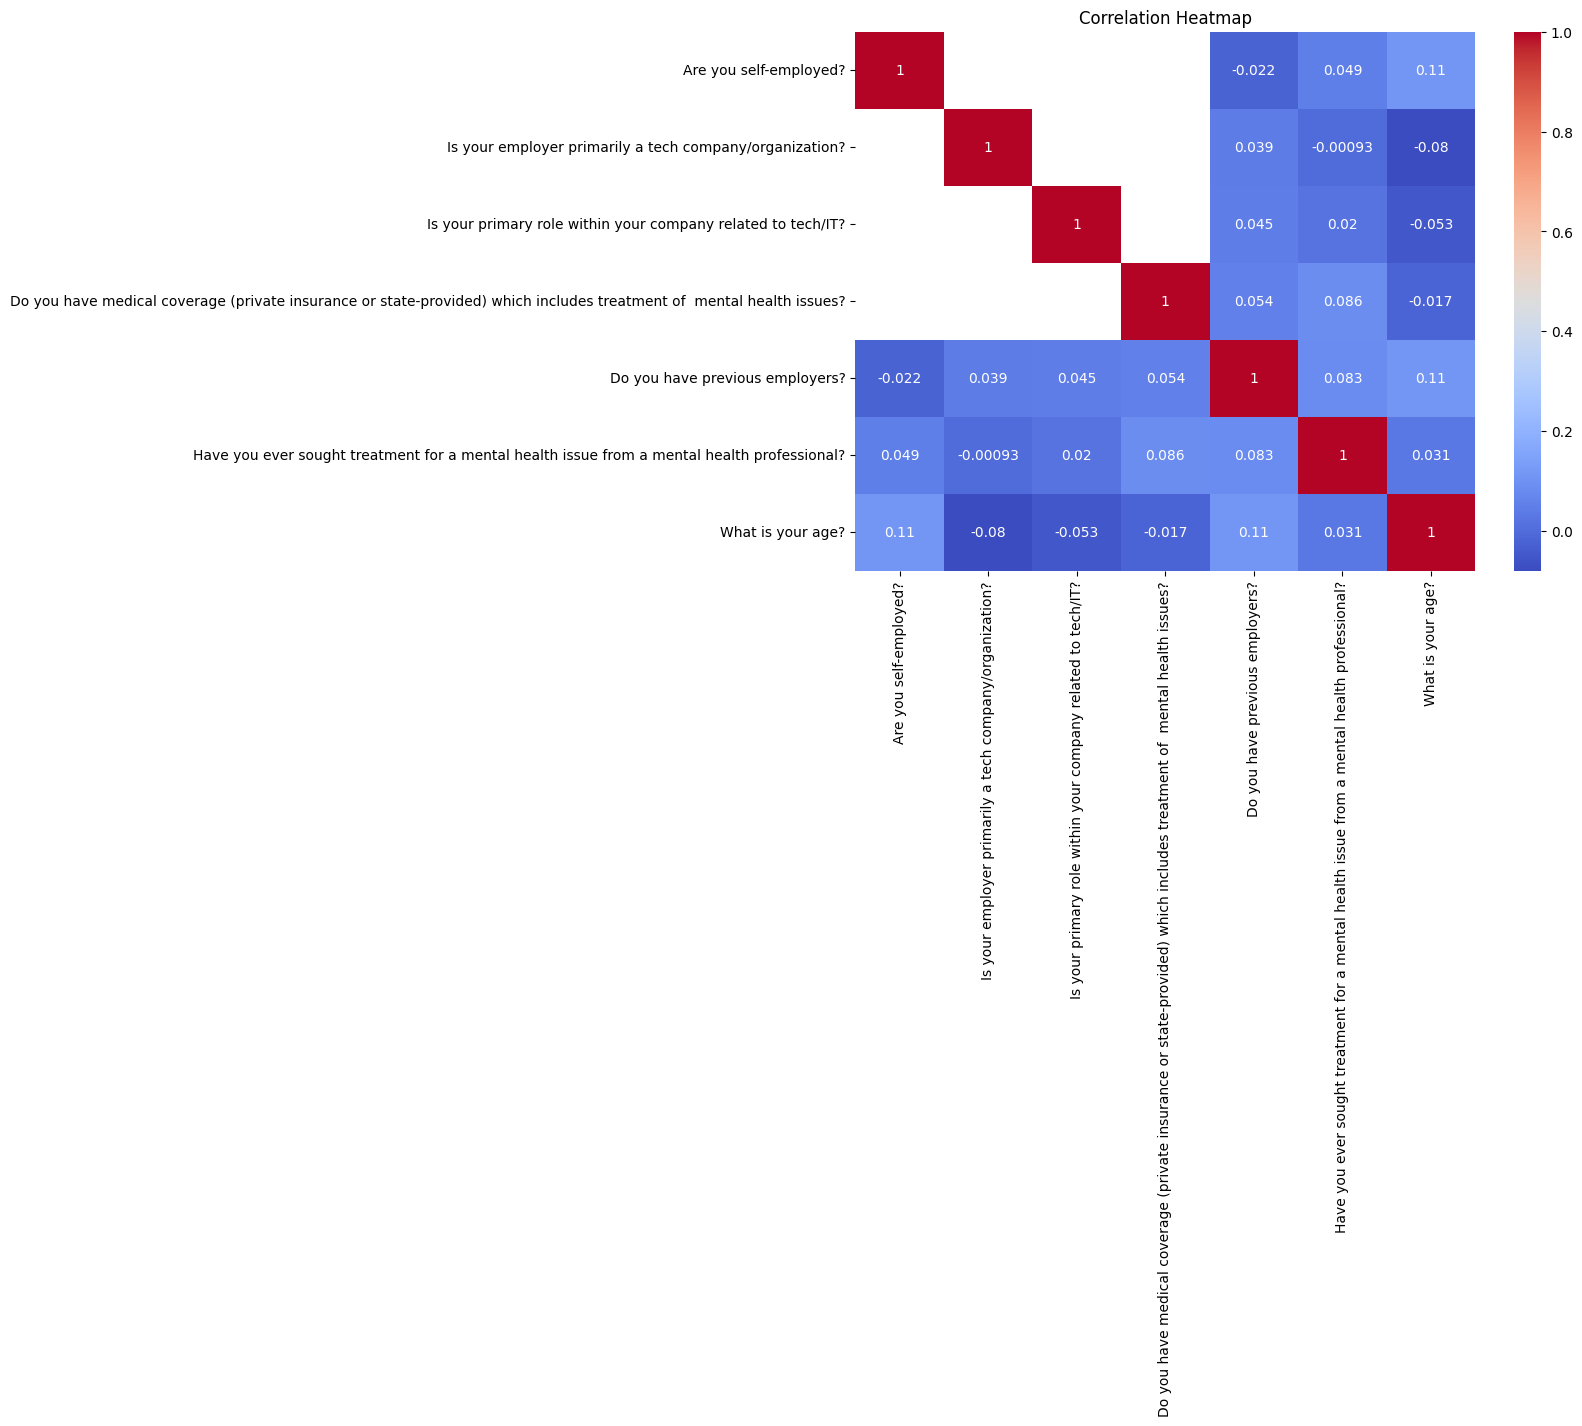

In [25]:
numeric_data = clean.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    cmap='coolwarm',
    annot=True
)

plt.title("Correlation Heatmap")
plt.show()

WEEK 4 – KEY OBSERVATIONS

1. The age graph shows the age distribution of survey respondents.
2. The gender graph displays the gender categories.
3. The treatment graph shows respondents who reported seeking mental health treatment.
4. Family history is compared with treatment-seeking responses.
5. Work interference is compared under treated and untreated conditions.
6. The correlation heatmap displays relationships between numerical variables.

Conclusion:
EDA helps identify patterns in mental health experiences and workplace factors among survey respondents.